# Assignment 08: Species Distribution Modeling with elapid

## BIO597 Spatial Analysis of Biodiversity

Use `elapid` to prepare spatial data, fit a MaxEnt model, and ask how evaluation changes when we withhold whole geographic areas. You may reuse code from Lab08.

## Deliverable

Submit this completed notebook with maps, climate comparisons, ROC curves, an AUC summary table, and short written answers. Save your modeling points and AUC table. Use the lab's model defaults; no parameter search or suitability-raster export is required.


## 1. Import packages and load the occurrence records

Run this notebook from `docs/assignments`. The imports are provided so you can focus on the SDM workflow. If elapid is unavailable, use the same environment or installation instructions as the lab.

`np.random.seed(597)` makes the background draws repeatable when the notebook runs from top to bottom.


In [1]:
pip install elapid rasterio scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 115.9 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [elapid]2m2/4 [rasterio]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import elapid as ela
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio import plot as rioplot
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.metrics import RocCurveDisplay

np.random.seed(597)
amphibians = gpd.read_file("../data/amphibians.geojson")
amphibians["species"].value_counts().head(12)


species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Name: count, dtype: int64

## 2. Choose a species

Choose a common Maine amphibian other than the lab's pickerel frog (*Lithobates palustris*). Start with at least 200 records. Filter the occurrence table to your species and store the result as `species_points`.


In [3]:
target_species = "Ambystoma maculatum"

# Select your species and store a copy as species_points.
# Print the record count and coordinate reference system.
species_points = amphibians[amphibians["species"] == target_species].copy()

print("Species:", target_species)
print("Record count:", len(species_points))
print("CRS:", species_points.crs)

Species: Ambystoma maculatum
Record count: 1317
CRS: EPSG:4326


**Why this species?** Give one biological reason for your choice. 
Spotted salamanders need areas with moisture to live and reproduce. A SDM with all the bioclimatic variables is a good way to predict their distributions in Maine as a function of these variables. Bio12 (annual precipitation) is a good climate variable to look at since it correlates the best with spotted salamander preferred climate conditions. 

## 3. Set up the climate rasters

Use the same 19 Maine bioclimatic rasters as the lab. The filenames and readable column names are provided below. Their order matters: each label must describe the corresponding raster.


In [4]:
bioclim_names = {
    'wc2.1_2.5m_bio_1.tif':  'Annual mean temperature',
    'wc2.1_2.5m_bio_2.tif':  'Mean diurnal temperature range',
    'wc2.1_2.5m_bio_3.tif':  'Isothermality',
    'wc2.1_2.5m_bio_4.tif':  'Temperature seasonality',
    'wc2.1_2.5m_bio_5.tif':  'Max temperature, warmest month',
    'wc2.1_2.5m_bio_6.tif':  'Min temperature, coldest month',
    'wc2.1_2.5m_bio_7.tif':  'Annual temperature range',
    'wc2.1_2.5m_bio_8.tif':  'Mean temperature, wettest quarter',
    'wc2.1_2.5m_bio_9.tif':  'Mean temperature, driest quarter',
    'wc2.1_2.5m_bio_10.tif': 'Mean temperature, warmest quarter',
    'wc2.1_2.5m_bio_11.tif': 'Mean temperature, coldest quarter',
    'wc2.1_2.5m_bio_12.tif': 'Annual precipitation',
    'wc2.1_2.5m_bio_13.tif': 'Precipitation, wettest month',
    'wc2.1_2.5m_bio_14.tif': 'Precipitation, driest month',
    'wc2.1_2.5m_bio_15.tif': 'Precipitation seasonality',
    'wc2.1_2.5m_bio_16.tif': 'Precipitation, wettest quarter',
    'wc2.1_2.5m_bio_17.tif': 'Precipitation, driest quarter',
    'wc2.1_2.5m_bio_18.tif': 'Precipitation, warmest quarter',
    'wc2.1_2.5m_bio_19.tif': 'Precipitation, coldest quarter',
}

rasters = [f"../data/bioclim_ME/{var}" for var in bioclim_names]
labels = list(bioclim_names.values())


## 4. Map the records over temperature

Open `rasters[0]` (annual mean temperature), plot it with `rioplot.show()`, and overlay your species' points. Reproject the points to the raster CRS when plotting, as in the lab. Keep this first raster path as `mean_temp_raster` for sampling.


/srv/conda/envs/notebook/lib/python3.13/site-packages/matplotlib/colors.py:816: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


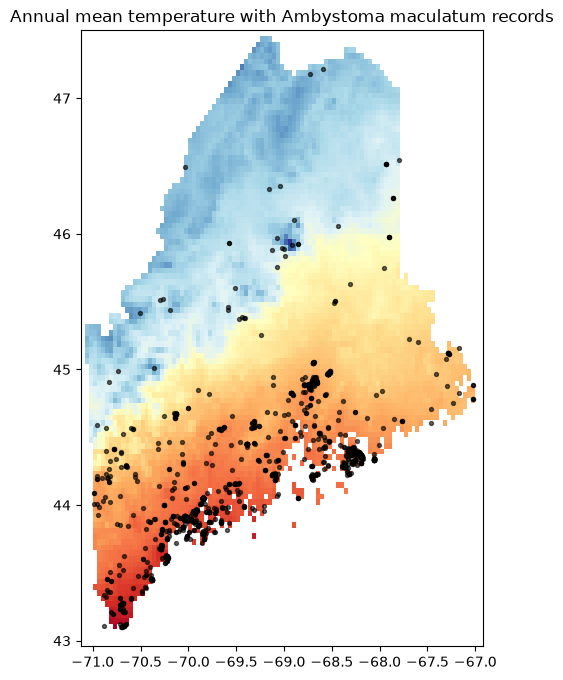

In [5]:
mean_temp_raster = rasters[0]

# Plot annual mean temperature and overlay species_points.
# Add a title naming your species.

with rio.open(mean_temp_raster) as src:
    raster_crs = src.crs
    points_for_plot = species_points.to_crs(raster_crs)

    fig, ax = plt.subplots(figsize=(8, 8))
    rioplot.show(src, ax=ax, cmap="RdYlBu_r")
    points_for_plot.plot(ax=ax, color="black", markersize=8, alpha=0.6)

ax.set_title(f"Annual mean temperature with {target_species} records")
plt.show()

**Interpretation:** Are records spread across Maine or concentrated in particular places? Why might a gap in records fail to indicate a true absence?
Spotted salamander records as a function of annual mean temperature shows that they are concentrated on the southern coast of Maine. Because a gap can mean that nobody has seen a spotted salamander there, but it doesn't mean that the spotted salamander could not have been there. It might have or it might not. 


## 5. Compare two background samples

Draw 1,000 points with `ela.sample_raster()` and another 1,000 with `ela.sample_bias_file()`, using annual mean temperature as the bias file. Drop duplicate geometries in each sample, following the lab, and report the remaining counts. Map the two samples side by side.

The biased sample favors cells with larger temperature values. This is a demonstration of sampling bias; temperature alone does not establish where observers actually searched.


Uniform sample, after dropping duplicates: 917
Biased sample, after dropping duplicates: 908


/srv/conda/envs/notebook/lib/python3.13/site-packages/matplotlib/colors.py:816: RuntimeWarning: overflow encountered in multiply
  xa *= self.N
/srv/conda/envs/notebook/lib/python3.13/site-packages/matplotlib/colors.py:816: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


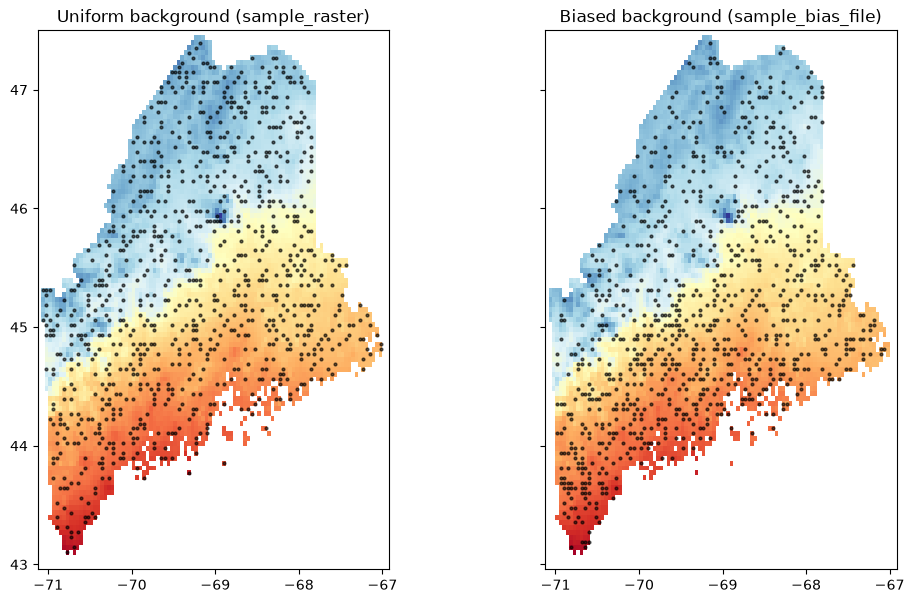

In [6]:
count = 1000

# Create pseudoabsence with ela.sample_raster().
# Create pseudoabsence_bias with ela.sample_bias_file().
# Drop duplicate points, print the remaining counts, and map both samples.

pseudoabsence = ela.sample_raster(mean_temp_raster, count=count)

pseudoabsence_bias = ela.sample_bias_file(mean_temp_raster, count=count)

pseudoabsence = pseudoabsence.drop_duplicates()
pseudoabsence_bias = pseudoabsence_bias.drop_duplicates()

print("Uniform sample, after dropping duplicates:", len(pseudoabsence))
print("Biased sample, after dropping duplicates:", len(pseudoabsence_bias))

with rio.open(mean_temp_raster) as src:
    fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharex=True, sharey=True)

    for ax, points, title in [
        (axes[0], pseudoabsence, "Uniform background (sample_raster)"),
        (axes[1], pseudoabsence_bias, "Biased background (sample_bias_file)"),
    ]:
        rioplot.show(src, ax=ax, cmap="RdYlBu_r")
        points.plot(ax=ax, color="black", markersize=4, alpha=0.6)
        ax.set_title(title)

plt.show()


**Interpretation:** How do the two geographic samples differ? Explain why background choice can change the species–climate relationship learned by a model. 
Uniform: Points are scattered evenly across the state. Biased: Points shift towards the warm south and the cold north is more sparse. With a uniform background, the model compares the spotted salamander occurrence records with the whole state of Maine. If the records show that the spotted salamander occurrence concentrates in the south, then the model learns that presence is associated with warmer temperature. With a temperature bias background, alot of the background points fall in the warm south, so they look like presence records in terms of temperature. 

Choose one sample for the remaining analysis and keep it fixed. The line below uses the uniform sample; change it to `pseudoabsence_bias` if you choose the biased sample.

**Background choice and justification:**
I chose uniform because it represents the climate conditions across Maine whereas the bias background will resemble the presence record for the wrong reason. The bias background thinks that the south is warm and heavily sampled but warmth isn't why it is being sampled.


In [7]:
background_points = pseudoabsence


## 6. Extract climate values with `ela.annotate()`

Annotate `species_points.geometry` and your chosen `background_points` using `rasters`, `labels`, `drop_na=True`, and `quiet=True`. Store the results as `presence` and `background`. Report the number of usable rows in each table.

Annotation means extracting raster values at point locations. `drop_na=True` removes points falling on raster NoData cells.


In [8]:

presence = ela.annotate(
    species_points.geometry,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

background = ela.annotate(
    background_points.geometry,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

print("Usable presence rows:", len(presence))
print("Usable background rows:", len(background))
presence.head()

Usable presence rows: 1214
Usable background rows: 917


,Annual mean temperature,Mean diurnal temperature range,Isothermality,Temperature seasonality,"Max temperature, warmest month","Min temperature, coldest month",Annual temperature range,"Mean temperature, wettest quarter","Mean temperature, driest quarter","Mean temperature, warmest quarter","Mean temperature, coldest quarter",Annual precipitation,"Precipitation, wettest month","Precipitation, driest month",Precipitation seasonality,"Precipitation, wettest quarter","Precipitation, driest quarter","Precipitation, warmest quarter","Precipitation, coldest quarter",geometry
0,7.011833,10.399667,27.971130,935.604248,25.464001,-11.716000,37.180000,-1.924000,18.308666,18.308666,-4.878000,1324.0,148.0,75.0,18.075323,404.0,257.0,257.0,357.0,POINT (-68.32814 44.41013)
1,3.071667,12.066000,27.480186,1125.005615,24.172001,-19.736000,43.908001,16.482000,-10.112667,16.482000,-11.418667,1032.0,109.0,54.0,19.164749,317.0,193.0,317.0,205.0,POINT (-69.04356 46.35532)
2,7.011833,10.399667,27.971130,935.604248,25.464001,-11.716000,37.180000,-1.924000,18.308666,18.308666,-4.878000,1324.0,148.0,75.0,18.075323,404.0,257.0,257.0,357.0,POINT (-68.32197 44.39384)
3,6.460667,11.390667,28.576685,996.660950,26.172001,-13.688000,39.860001,-3.332667,18.511333,18.511333,-6.271333,1163.0,120.0,81.0,11.492370,333.0,262.0,262.0,295.0,POINT (-68.38665 44.76424)
4,3.205833,12.007000,27.420753,1127.029297,24.271999,-19.516001,43.788002,16.650000,-10.018666,16.650000,-11.295334,1032.0,107.0,54.0,18.279444,313.0,194.0,313.0,204.0,POINT (-69.1549 46.32885)


## 7. Compare recorded and available environments

Use the plotting recipe below to compare annual mean temperature, annual precipitation, and precipitation seasonality. These are the same three variables considered in Lab07. Density-scaled histograms let us compare shapes despite different sample sizes.


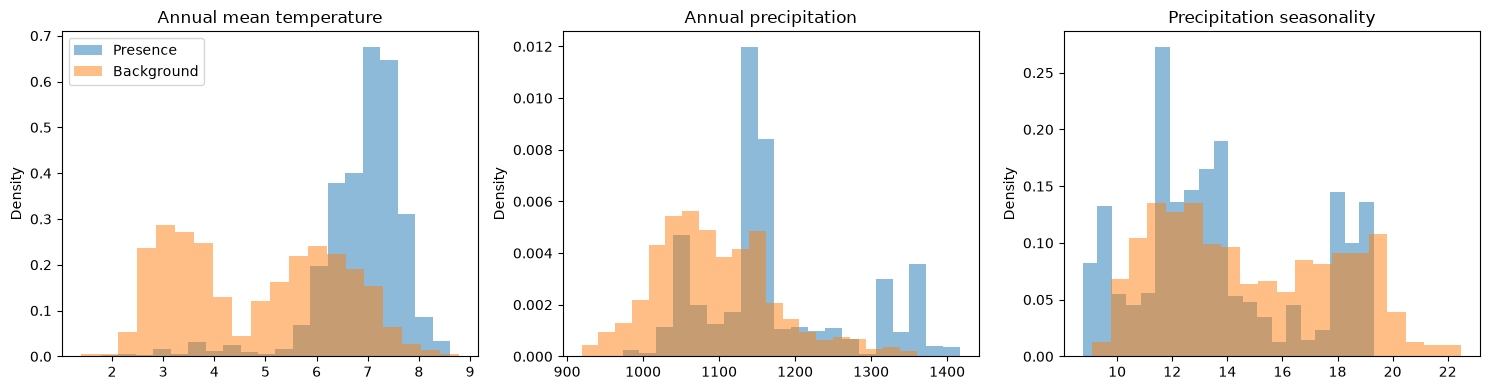

In [9]:
comparison_labels = [labels[0], labels[11], labels[14]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for label, ax in zip(comparison_labels, axes):
    ax.hist(presence[label], bins=20, density=True, alpha=0.5, label="Presence")
    ax.hist(background[label], bins=20, density=True, alpha=0.5, label="Background")
    ax.set_title(label)
    ax.set_ylabel("Density")

axes[0].legend()
plt.tight_layout()
plt.show()


**Interpretation:** Choose one variable. Does your species' recorded environment differ from the sampled background? Describe the pattern without assuming it proves a habitat preference. 
I chose annual mean temperature. Yes, my species's recorded environment is different from the sampled background. The difference between presence and backgrond is the clearest with the annual mean temperature variable. 

## 8. Calculate geographic sample weights

Following the lab, use `ela.distance_weights(..., n_neighbors=-1)` to calculate a `SampleWeight` column separately for presence and background. Pass points projected to `EPSG:26919`, which uses meters. Plot presence points colored by their weights.

The weights give relatively isolated observations more influence than observations in dense clusters. They do not turn an unobserved location into a confirmed absence.


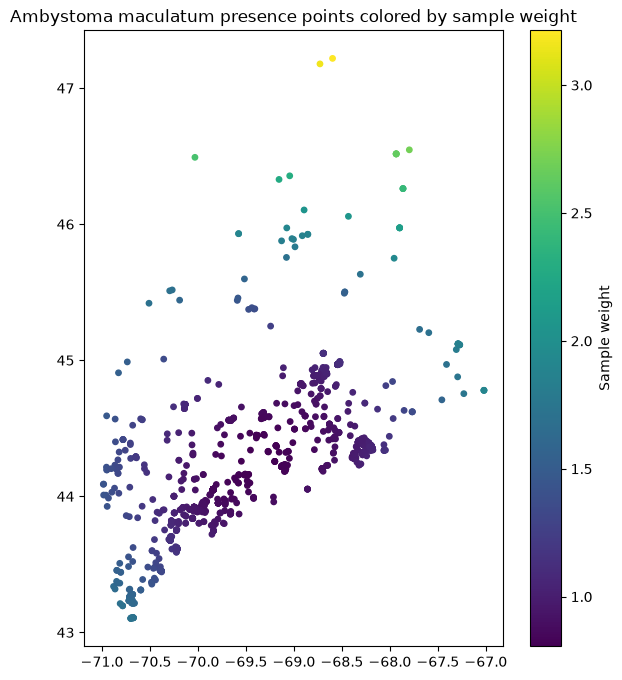

In [10]:
# Calculate presence["SampleWeight"] using presence.to_crs("EPSG:26919").
# Calculate background["SampleWeight"] the same way.
# Plot the presence weights with a legend.

presence["SampleWeight"] = ela.distance_weights(
    presence.to_crs("EPSG:26919"),
    n_neighbors=-1,
)

background["SampleWeight"] = ela.distance_weights(
    background.to_crs("EPSG:26919"),
    n_neighbors=-1,
)

ax = presence.plot(
    column="SampleWeight",
    cmap="viridis",
    markersize=15,
    legend=True,
    legend_kwds={"label": "Sample weight"},
    figsize=(7, 8),
)
ax.set_title(f"{target_species} presence points colored by sample weight")
plt.show()


**Interpretation:** Where are the largest weights? Why would decimal degrees be a poor unit for the distance calculations?
The largest weights are at the very top north. Decimal degrees aren't a fixed length. 

## 9. Stack the tables and define predictors

Use `ela.stack_geodataframes(presence, background, add_class_label=True)` and project the result to `EPSG:26919`. Call the result `merged` and display the counts in its `class` column.

`class` is 1 for presence and 0 for background. Select only the named climate columns as predictors. `SampleWeight`, class labels, geometry, and later split labels must stay out of the predictor table.


In [11]:
# Stack presence and background as merged, then project it to EPSG:26919.
# Display the counts of each class.


merged = ela.stack_geodataframes(presence, background, add_class_label=True)
merged = merged.to_crs("EPSG:26919")

merged["class"].value_counts()

X = merged[labels]
y = merged["class"]
sample_weight = merged["SampleWeight"]




## 10. Fit MaxEnt and calculate a training AUC

Create `maxent = ela.MaxentModel()` and fit it with `X`, `y`, and `sample_weight=sample_weight`. Predict scores for `X`.

This first check uses the same rows for learning and evaluation, as in the lab's “naive” model. It is a **training score**, not a test of new locations.

**ROC AUC** measures how well scores rank presence above background. A value near 0.5 indicates little ranking ability; a higher value indicates better separation of these labels. The ROC curve shows the tradeoff as we change the cutoff for calling a score high: more recorded presences exceed the cutoff, but more background points may exceed it too. AUC does not establish true occupancy probability.


Naive AUC:          0.932
Naive weighted AUC: 0.916


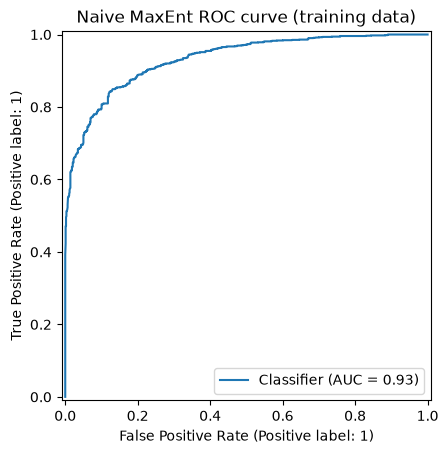

In [12]:
maxent = ela.MaxentModel()
maxent.set_params(n_cpus=4)

# Fit maxent with X, y, and sample_weight.
# Predict X and store the scores as naive_prediction.
# Calculate naive_auc with metrics.roc_auc_score(y, naive_prediction).
# Also calculate naive_weighted_auc using sample_weight=sample_weight.
# Print both scores and plot a ROC curve with RocCurveDisplay.from_predictions().

maxent.fit(X, y, sample_weight=sample_weight)

naive_prediction = maxent.predict(X)

naive_auc = metrics.roc_auc_score(y, naive_prediction)

naive_weighted_auc = metrics.roc_auc_score(y, naive_prediction, sample_weight=sample_weight)

print(f"Naive AUC:          {naive_auc:.3f}")
print(f"Naive weighted AUC: {naive_weighted_auc:.3f}")

RocCurveDisplay.from_predictions(y, naive_prediction)
plt.title("Naive MaxEnt ROC curve (training data)")
plt.show()

**Interpretation:** Why might evaluating the same rows used to fit a model give an overly encouraging impression of performance?
It's because the model has already seen the answers. Maxent is fitted exactly to these rows so it's adjusted to ranking them well. 

## 11. Make a geographic train/test split

Use `ela.checkerboard_split(merged, grid_size=50_000)` to divide points into alternating 50 km squares. This distance is in meters because `merged` is projected.

Check the class counts in both groups: each needs presence and background rows to calculate AUC. The provided plotting recipe adds a split label for display only.


Training labels:
class
1    802
0    474
Name: count, dtype: int64
Test labels:
class
0    442
1    411
Name: count, dtype: int64


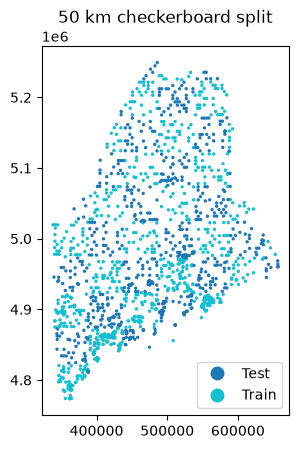

In [13]:
grid_size = 50_000
train, test = ela.checkerboard_split(merged, grid_size=grid_size)
print("Training labels:")
print(train["class"].value_counts())
print("Test labels:")
print(test["class"].value_counts())

train["split"] = "Train"
test["split"] = "Test"
checker = ela.stack_geodataframes(train, test)
checker.plot(column="split", markersize=2, legend=True)
plt.title("50 km checkerboard split")
plt.show()


## 12. Refit using training points and evaluate test points

Build training and test predictor tables using only `labels`, as below. Refit `maxent` on the training rows and their weights, then predict the test rows. Calculate unweighted and weighted test AUCs, storing them as `checker_auc` and `checker_weighted_auc`. Plot the test ROC curve.

In weighted AUC, test weights affect the contribution of each test row. They do not mean the model learned from the test labels.


Checkerboard test AUC:          0.791
Checkerboard test weighted AUC: 0.755


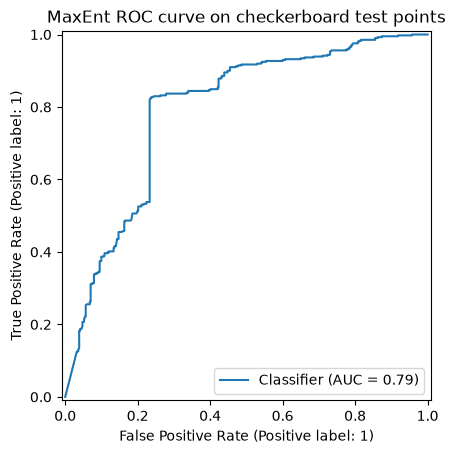

In [14]:
Xtrain = train[labels]
ytrain = train["class"]
weight_train = train["SampleWeight"]
Xtest = test[labels]
ytest = test["class"]
weight_test = test["SampleWeight"]

# Fit maxent using only Xtrain, ytrain, and weight_train.
# Predict Xtest and calculate checker_auc and checker_weighted_auc.
# Print the scores and plot the test ROC curve.

maxent.fit(Xtrain, ytrain, sample_weight=weight_train)

checker_prediction = maxent.predict(Xtest)

checker_auc = metrics.roc_auc_score(ytest, checker_prediction)
checker_weighted_auc = metrics.roc_auc_score(ytest, checker_prediction, sample_weight=weight_test)

print(f"Checkerboard test AUC:          {checker_auc:.3f}")
print(f"Checkerboard test weighted AUC: {checker_weighted_auc:.3f}")

RocCurveDisplay.from_predictions(ytest, checker_prediction)
plt.title("MaxEnt ROC curve on checkerboard test points")
plt.show()


## Apply the trained model to the ME clipped rasters

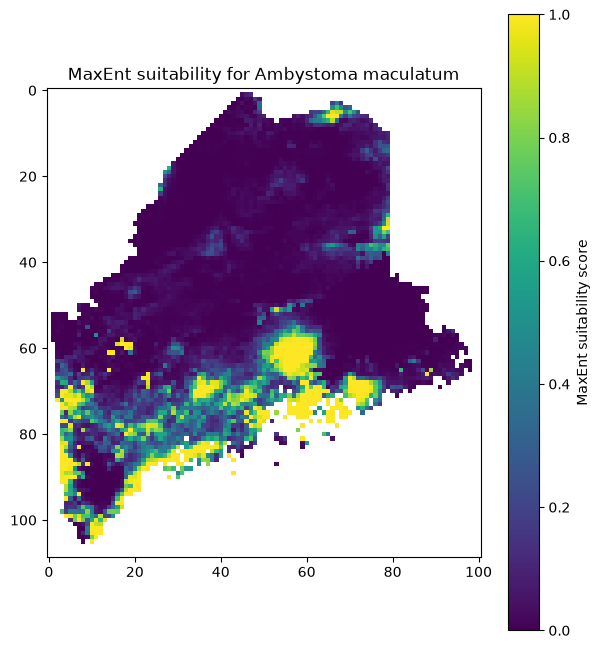

In [15]:
output_raster = "Assignment08_suitability.tif"
# Use ela.apply_model_to_rasters() to apply the fitted model to the raster stack
# and write the result to the output_raster file

# use rio.open() to read the predicted tif back into memory
# and plot it with imshow()
ela.apply_model_to_rasters(
    maxent,
    rasters,
    output_raster,
    quiet=True,
)

with rio.open(output_raster) as src:
    suitability_map = src.read(1, masked=True)

plt.figure(figsize=(7, 8))
plt.imshow(suitability_map, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="MaxEnt suitability score")
plt.title(f"MaxEnt suitability for {target_species}")
plt.show()




**Interpretation:** Did test AUC differ from training AUC? Describe what each score evaluates. A lower test score does not automatically prove that spatial autocorrelation caused the difference: the training size and environments also changed. A higher test score does not automatically establish a reliable map.
The test AUC was lower than the training AUC. Training AUC is how well the model ranks presence above background on the same rows it was fitted to. Test AUC, is how the model fits on the training squares and ranks presence above background 50 km, it never saw.
## 13. Give the other squares a turn

For a simple two-fold spatial cross-validation, reverse the roles: create a new MaxEnt model, train it using `Xtest`, `ytest`, and `weight_test`, then evaluate its predictions for `Xtrain`. Store the unweighted and weighted scores as `reverse_auc` and `reverse_weighted_auc`.

No new background draw or checkerboard split is needed.


In [16]:
# Create reverse_model with the same settings.
# Fit on Xtest with ytest and weight_test; predict Xtrain.
# Calculate reverse_auc and reverse_weighted_auc against ytrain.
# Print the scores.


reverse_model = ela.MaxentModel()
reverse_model.set_params(n_cpus=4)

reverse_model.fit(Xtest, ytest, sample_weight=weight_test)
reverse_prediction = reverse_model.predict(Xtrain)

reverse_auc = metrics.roc_auc_score(ytrain, reverse_prediction)
reverse_weighted_auc = metrics.roc_auc_score(ytrain, reverse_prediction, sample_weight=weight_train)

print(f"Reverse test AUC:          {reverse_auc:.3f}")
print(f"Reverse test weighted AUC: {reverse_weighted_auc:.3f}")

Reverse test AUC:          0.757
Reverse test weighted AUC: 0.738


**Interpretation:** Were the two directions equally easy to predict? Suggest one geographic or biological reason for a difference. Swapping the regions gives each group a turn as test data; it does not remove every source of observation bias.
The reverse direction was harder to predict. The two groups cover different parts of Maine, so one half contains climates the other one doesn't. 

## 14. Inspect one buffered leave-one-out split

The lab also demonstrates buffered leave-one-out validation. For each test presence, it removes nearby training points so the model must predict farther from its training data.

Run the code below to inspect **one split**, using a 50 km buffer. No repeated model fitting is required here. `next()` takes just the first split that the splitter produces. This visualization is not a complete validation or an AUC estimate.


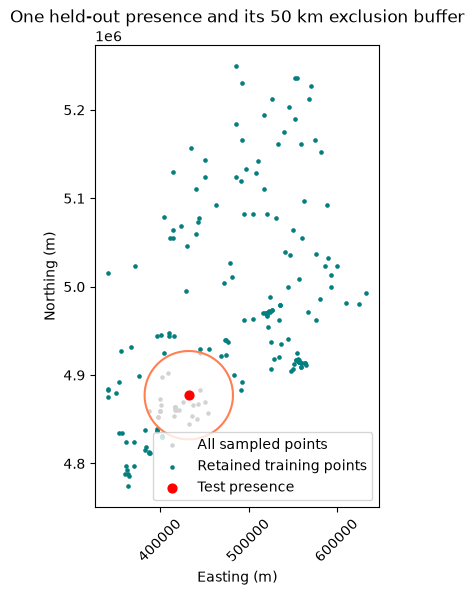

In [17]:
subset = merged.sample(n=min(200, len(merged)), random_state=597).reset_index(drop=True)
distance = 50_000
bloo = ela.BufferedLeaveOneOut(distance=distance)
train_idx, test_idx = next(bloo.split(subset, class_label="class"))
buffer_train = subset.iloc[train_idx]
buffer_test = subset.iloc[test_idx]

fig, ax = plt.subplots(figsize=(6, 6))
subset.plot(ax=ax, color="lightgray", markersize=5, label="All sampled points")
buffer_train.plot(ax=ax, color="teal", markersize=5, label="Retained training points")
buffer_test.buffer(distance).boundary.plot(ax=ax, color="coral")
buffer_test.plot(ax=ax, color="red", markersize=40, label="Test presence")
ax.legend()
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.tick_params(axis="x", labelrotation=45)
ax.set_title("One held-out presence and its 50 km exclusion buffer")
plt.show()


**Interpretation:** What happened to points inside the buffer? How does this test a different prediction question from randomly withholding records? Explain why a single held-out presence cannot by itself give a ROC AUC.
The points inside the 50 km buffer around the held-out presence were removed from the training set, thiis leaves only points that are 50 km away. This oberservation tests a different question from random with holding. Random withholding lets the model use near-duplicate neighbors with the same climate, while buffered leave-one-out asks whether it can predict a location with no nearby training data, closer to predicting an unsampled place. A single held-out presence cannot give a ROC AUC because AUC compares scores of presence and background rows and needs both classes and many scores to trace the curve.
## 15. Summarize and save your results

Make a three-row table with evaluation names, unweighted AUCs, and weighted AUCs:

* Training rows scored by the all-data model.
* First checkerboard direction: train on `train`, evaluate `test`.
* Reversed direction: train on `test`, evaluate `train`.

Save it as `Assignment08_auc_scores.csv`, without a DataFrame index. Save `merged` as `Assignment08_modeling_points.gpkg` using `driver="GPKG"`, preserving its geometry, climate columns, labels, weights, and projected CRS.


In [19]:

auc_summary = pd.DataFrame({
    "evaluation": [
        "Training rows, all-data model",
        "Checkerboard: train on train, evaluate test",
        "Reversed: train on test, evaluate train",
    ],
    "auc": [naive_auc, checker_auc, reverse_auc],
    "weighted_auc": [naive_weighted_auc, checker_weighted_auc, reverse_weighted_auc],
})

auc_summary = auc_summary.round(3)
display(auc_summary)

auc_summary.to_csv("Assignment08_auc_scores.csv", index=False)

merged.to_file("Assignment08_modeling_points.gpkg", driver="GPKG")

,evaluation,auc,weighted_auc
0,"Training rows, all-data model",0.932,0.916
1,"Checkerboard: train on train, evaluate test",0.791,0.755
2,"Reversed: train on test, evaluate train",0.757,0.738


## Final reflection

Answer each question in two or three sentences, using your results.

1. Which preparation tasks did elapid simplify compared with earlier labs?
Elapid simplified drawing background points, it extracted climate values at points and dropped NoData cells in one step. It calculated geographic sample weights, stacking presence and background with class labels, creating spatially blocked train/test splits, fitting a MaxEnt model that accepts weights, and applying the model to the raster stack to write a suitability map.
    
2. What do background sampling, geographic sample weights, and spatial train/test splitting each change?
Background sampling changes what the model is compared against. Sample weights change how much each record counts, and spatial splitting changes how performance gets judged.
    
3. Why do high AUC and a convincing ROC curve not establish a probability that your species occurs at a location?
Because AUC and the ROC curve describe how well the model ranks rows, not what the scores mean as chances. There are several things that separate a good ranking from a probability of occurrence.

4. What additional data or evaluation would most improve confidence in predictions for your species?
Maybe use records from repeated visits to s certain area, like a vernal pool. Confirm absences let you evaluate whether low scores really reflect the organismal prescence in that area. 


## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, AUC table, saved points, and written answers. Commit and push the completed notebook and the two output files to your class GitHub repository.

```bash
git add docs/assignments/Assignment-08-SDM-Software.ipynb docs/assignments/Assignment08_auc_scores.csv docs/assignments/Assignment08_modeling_points.gpkg
git commit -m "Complete elapid SDM assignment"
git push
```

## References

* [elapid geospatial tools](https://earth-chris.github.io/elapid/module/geo/)
* [elapid MaxEnt model](https://earth-chris.github.io/elapid/sdm/maxent/)
* [elapid spatial train/test splitting](https://earth-chris.github.io/elapid/module/train_test_split/)
